# Gaussian Naive Bayes

**Review 2 - Classification Part A - target: transmission**

This project-native rerun uses the same balanced 2,500-row UK dataset, fixed 80:20 split,
feature engineering and fold-safe preprocessing as every other classifier in TORQUEX.
The original Review 1 score is not reused. Part A keeps the established baseline settings;
five-fold cross-validation evaluates the model but does not tune it.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import GridSearchCV, cross_validate
import joblib

from src.classification import *


## 2. Dataset audit, target definition and preprocessing

In [2]:
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]

display(
    pd.DataFrame(
        {
            "Raw": raw[TARGET].value_counts(),
            "Cleaned": df[TARGET].value_counts(),
            "Train": y_train.value_counts(),
            "Test": y_test.value_counts(),
        }
    )
)
display(df.dtypes.to_frame("dtype").astype(str))
print("Raw shape:", raw.shape)
print("Cleaned shape:", df.shape)
print("Removed exact duplicate rows:", len(raw) - len(df))
print("Training rows:", len(train), "| Held-out test rows:", len(test))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)


Raw shape: (2500, 10)
Cleaned shape: (2500, 10)
Removed exact duplicate rows: 0
Training rows: 2000 | Held-out test rows: 500


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


## 3. Required EDA

Cleaned shape: (2500, 10) | Training: 2000 | Test: 500
Missing training values:
 brand            0
model            0
year             0
price_gbp        0
mileage_miles    0
fuel_type        0
tax_gbp          0
mpg_uk           0
engine_size_l    0
transmission     0
Training IQR outlier counts (retained; log transforms reduce skew):
car_age           38
log_price         22
log_mileage       74
tax_gbp          642
mpg_uk            20
engine_size_l    147


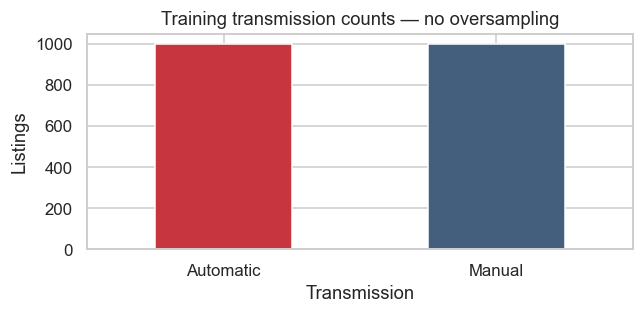

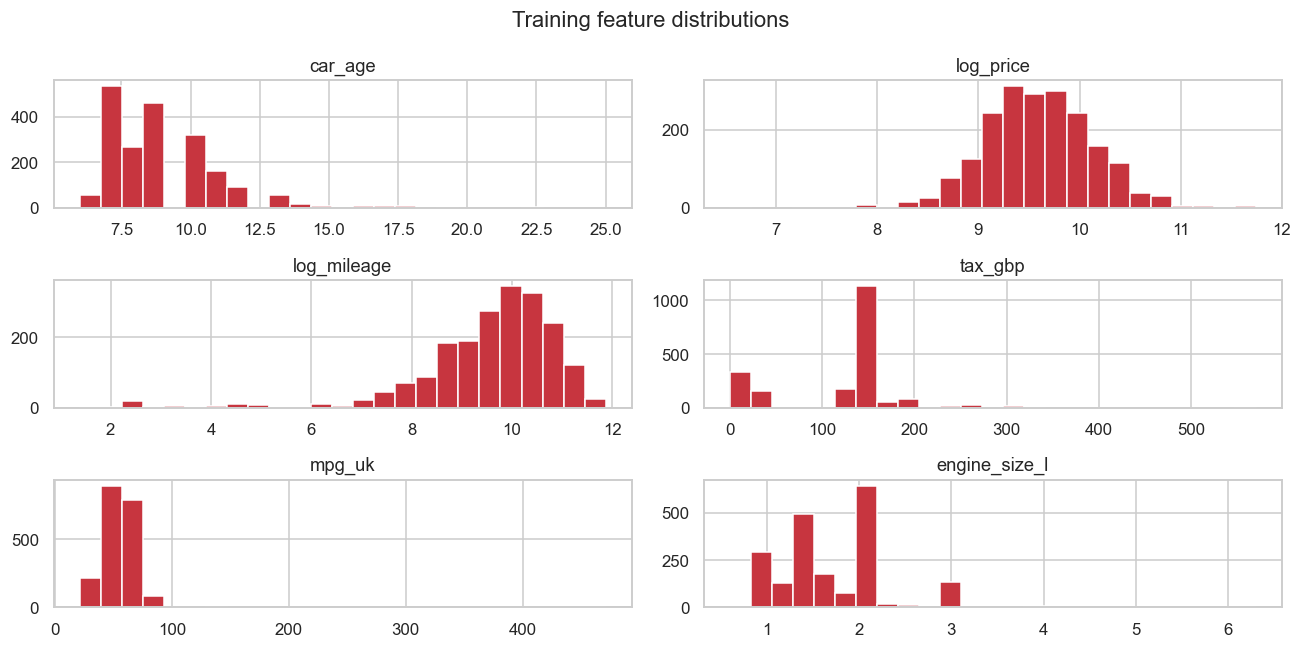

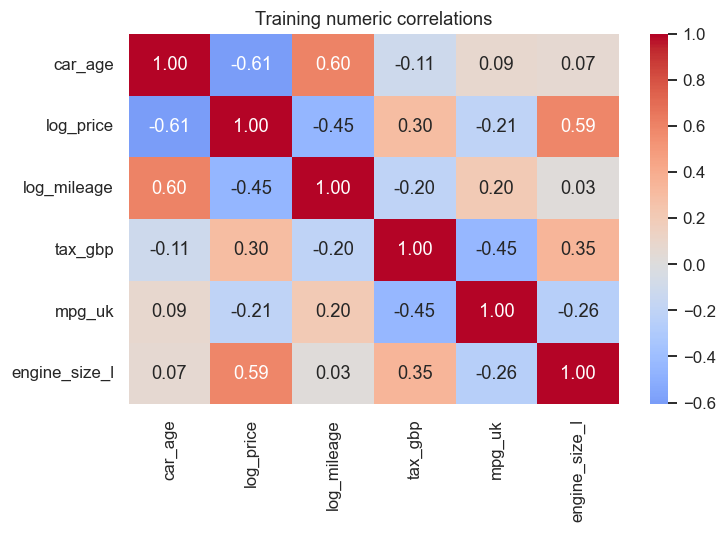

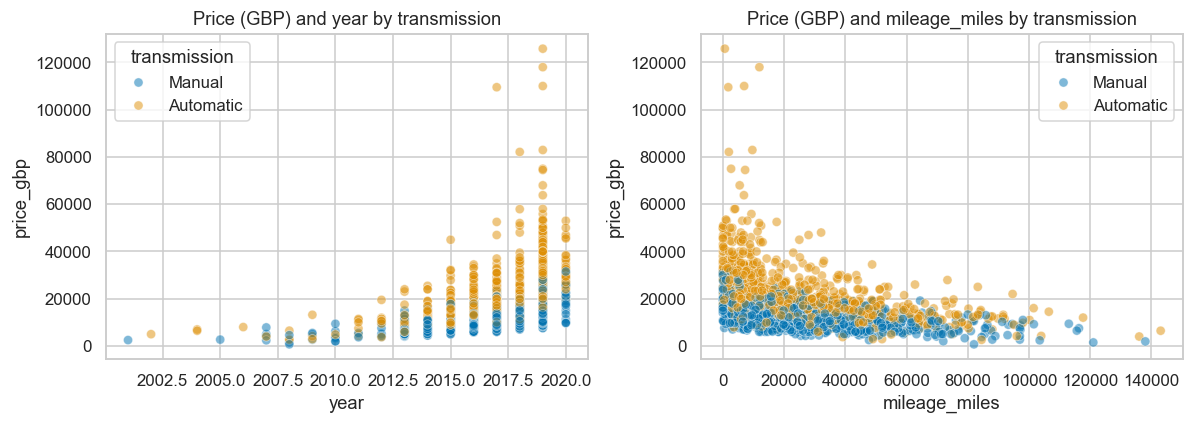

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
brand,2000,9,Ford,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,2000,143,Fiesta,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2000.0,NaN,NaN,NaN,2016.9735,2.129569,2001.0,2016.0,2017.0,2019.0,2020.0
price_gbp,2000.0,NaN,NaN,NaN,17001.7955,10392.673128,694.0,10417.25,14492.0,20900.0,125796.0
mileage_miles,2000.0,NaN,NaN,NaN,24529.251,21740.610165,3.0,8121.75,18820.0,34000.0,143000.0
fuel_type,2000,4,Petrol,1001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax_gbp,2000.0,NaN,NaN,NaN,120.4075,67.327468,0.0,125.0,145.0,145.0,570.0
mpg_uk,2000.0,NaN,NaN,NaN,55.725,17.138348,21.4,46.3,55.4,63.15,470.8
engine_size_l,2000.0,NaN,NaN,NaN,1.7235,0.577472,0.6,1.4,1.6,2.0,6.3
transmission,2000,2,Manual,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


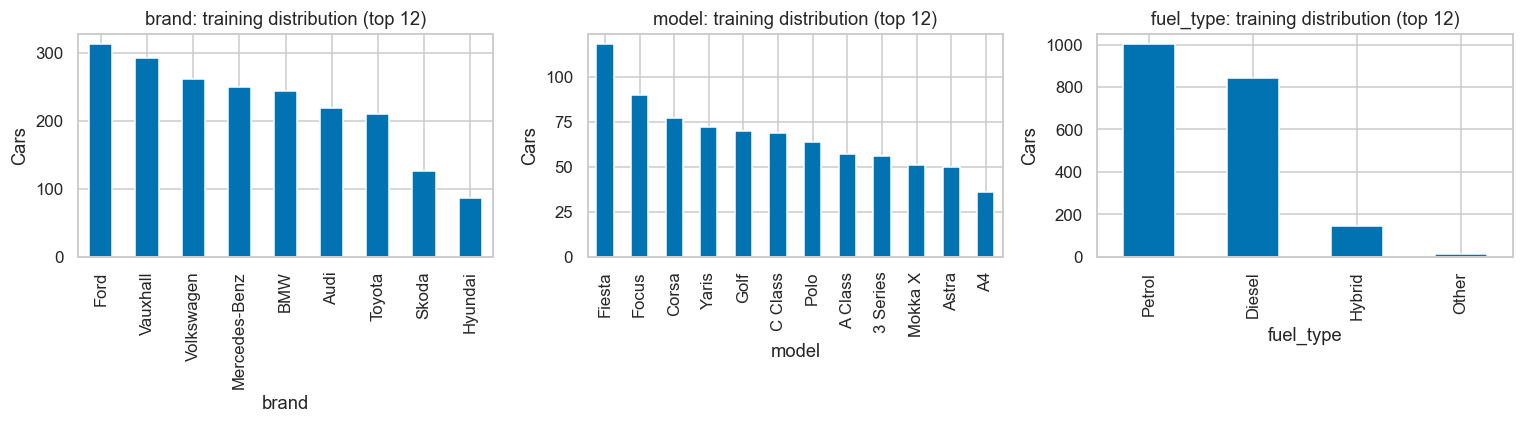

In [3]:
audit_plots(df, train)
display(train.describe(include="all").T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
engineered_train = CarFeatures().transform(X_train)
for axis, column in zip(axes.ravel(), ["brand", "model", "fuel_type"]):
    engineered_train[column].value_counts().head(12).plot.bar(ax=axis)
    axis.set(
        title=f"{column}: training distribution (top 12)",
        xlabel=column,
        ylabel="Cars",
    )
plt.tight_layout()
plt.show()


## 4. Model training and tuning

Part A is intentionally a baseline rerun, so no hyperparameter search is performed. The complete pipeline is still evaluated with five-fold stratified cross-validation.

In [4]:
slug = "naive_bayes"
name, estimator = part_a_models()[slug]
model = build_pipeline(clone(estimator))

print("Baseline estimator:")
display(estimator)
print("No parameter grid: this is the comparable Part A baseline rerun.")

Baseline estimator:
No parameter grid: this is the comparable Part A baseline rerun.


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [5]:
with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always")
    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        error_score="raise",
    )
    model.fit(X_train, y_train)

warning_messages = sorted({str(item.message) for item in captured})
display(pd.DataFrame({key: value for key, value in cv_result.items() if key.startswith("test_")}))
print("Mean training CV macro F1:", cv_result["test_f1_macro"].mean())
print("Recorded training warnings:", warning_messages or "None")

Mean training CV macro F1: 0.6770231639922046
Recorded training warnings: None


,test_f1_macro,test_f1_weighted,test_balanced_accuracy
0,0.712703,0.712703,0.7325
1,0.677341,0.677341,0.7000
2,0.661428,0.661428,0.6875
3,0.680865,0.680865,0.7050
4,0.652778,0.652778,0.6800


## 5. Evaluation

In [6]:
result = pd.DataFrame(
    [
        {
            "Slug": slug,
            "Model": name,
            "Part": "A rerun",
            "Stage": "Baseline",
            **metrics(model, X_test, y_test),
            "CV_macro_F1": float(cv_result["test_f1_macro"].mean()),
            "CV_macro_F1_std": float(cv_result["test_f1_macro"].std()),
        }
    ]
)
display(result.round(4))
display(
    pd.DataFrame(
        classification_report(
            y_test,
            model.predict(X_test),
            output_dict=True,
            zero_division=0,
        )
    ).T.round(4)
)

output_dir = ROOT / "results" / slug
output_dir.mkdir(parents=True, exist_ok=True)
result.to_csv(output_dir / "comparison.csv", index=False)
pd.DataFrame(
    {key: value for key, value in cv_result.items() if key.startswith("test_")}
).to_csv(output_dir / "baseline_cv_folds.csv", index=False)
pd.DataFrame(
    classification_report(
        y_test,
        model.predict(X_test),
        output_dict=True,
        zero_division=0,
    )
).T.to_csv(output_dir / "before_class_report.csv")
joblib.dump(model, ROOT / "models" / f"{slug}_before.joblib", compress=3)

metadata = {
    "selection_metric": "Five-fold training CV macro F1 (evaluation only; no Part A tuning)",
    "positive_class": "Automatic",
    "warnings": warning_messages,
    "test_used_for_tuning": False,
}
(output_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2, default=str), encoding="utf-8"
)

Out[6]: 178


,Slug,Model,Part,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,naive_bayes,Gaussian Naive Bayes,A rerun,Baseline,0.67,0.7807,0.67,0.6339,0.6339,0.67,0.957,0.356,0.8449,0.8569,0.677,0.0206


,precision,recall,f1-score,support
Automatic,0.9570,0.356,0.5190,250.00
Manual,0.6044,0.984,0.7489,250.00
accuracy,0.6700,0.670,0.6700,0.67
macro avg,0.7807,0.670,0.6339,500.00
weighted avg,0.7807,0.670,0.6339,500.00


## 6. Confusion matrix and model interpretation

This estimator does not expose direct coefficients or feature importances.


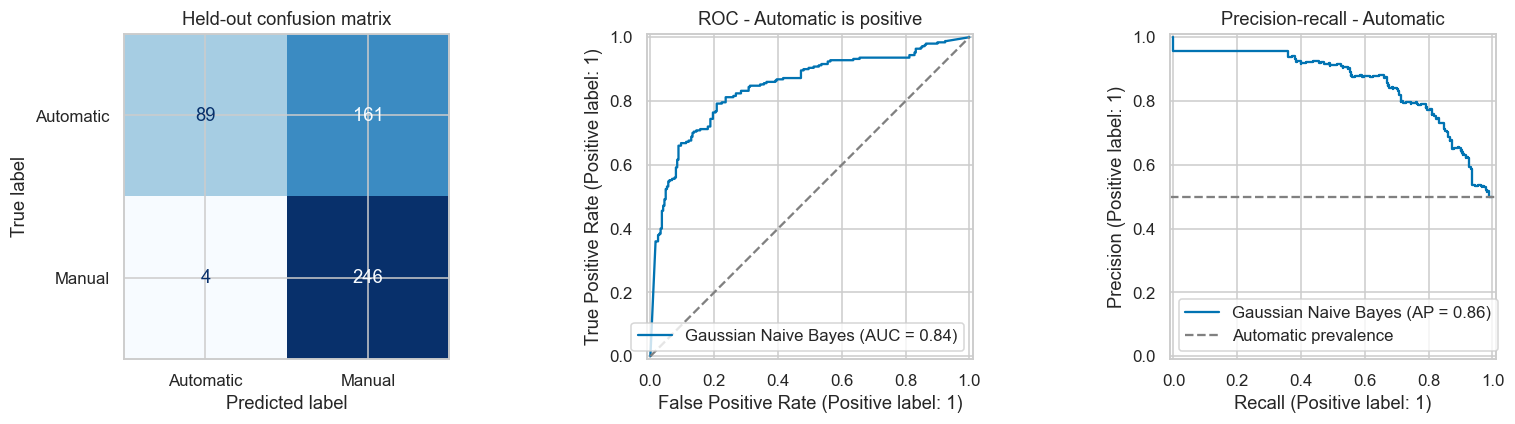

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    labels=["Automatic", "Manual"],
    display_labels=["Automatic", "Manual"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Held-out confusion matrix")

automatic_scores = automatic_probability(model, X_test)
automatic_target = (y_test == "Automatic").astype(int)
RocCurveDisplay.from_predictions(
    automatic_target, automatic_scores, name=name, ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC - Automatic is positive")

PrecisionRecallDisplay.from_predictions(
    automatic_target, automatic_scores, name=name, ax=axes[2]
)
axes[2].axhline(
    automatic_target.mean(), linestyle="--", color="gray", label="Automatic prevalence"
)
axes[2].legend()
axes[2].set_title("Precision-recall - Automatic")
plt.tight_layout()
plt.show()

fitted_estimator = model.named_steps["model"]
feature_names = model.named_steps["preprocess"].get_feature_names_out()
if hasattr(fitted_estimator, "feature_importances_"):
    importance = pd.Series(
        fitted_estimator.feature_importances_, index=feature_names
    ).nlargest(15).sort_values()
    importance.plot.barh(figsize=(8, 5), color="#128276")
    plt.title("Top feature importances")
    plt.xlabel("Impurity-based importance")
    plt.tight_layout()
    plt.show()
elif hasattr(fitted_estimator, "coef_"):
    coefficients = pd.Series(fitted_estimator.coef_[0], index=feature_names)
    strongest = coefficients.loc[
        coefficients.abs().nlargest(15).index
    ].sort_values()
    strongest.plot.barh(figsize=(8, 5), color="#128276")
    plt.title("Strongest signed coefficients")
    plt.xlabel("Coefficient")
    plt.tight_layout()
    plt.show()
else:
    print("This estimator does not expose direct coefficients or feature importances.")

## 7. Observation / Interpretation

**Observation:** This notebook uses **Gaussian Naive Bayes** to predict `transmission`
(Automatic or Manual) from the available car features.

- Cleaning, feature engineering and the fixed split are shared by all ten classifiers.
- Numeric and categorical preprocessing is fitted inside each training fold to avoid leakage.
- Five-fold macro F1 evaluates the Part A baseline; the held-out test set is used only for final reporting.
- Accuracy, weighted precision/recall/F1, macro F1, balanced accuracy, ROC-AUC and the confusion matrix are reported.
- **Model-specific observation:** Gaussian Naive Bayes estimates class probabilities under conditional-independence and Gaussian feature assumptions.

**Team task:** Discuss the actual metric values, class-specific errors and limitations visible in the executed output. Do not assume a performance value that is not displayed.